# Business Data Intelligence Platform

**Project type:** End-to-end retail data analysis and business intelligence

This notebook loads the UCI Online Retail dataset, profiles data quality, classifies transaction exceptions, analyses revenue and business performance, and exports reusable reports.

**Dataset source:** [UCI Machine Learning Repository — Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail)


In [1]:

import io
import zipfile
import requests
import pandas as pd
from pathlib import Path

DATA_URL = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

response = requests.get(DATA_URL, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
    excel_files = [
        name for name in archive.namelist()
        if name.lower().endswith((".xlsx", ".xls"))
    ]

    if not excel_files:
        raise FileNotFoundError("No Excel dataset found in archive.")

    with archive.open(excel_files[0]) as file:
        df = pd.read_excel(file)

print("Dataset loaded successfully")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


Dataset loaded successfully
Rows: 541909
Columns: 8

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 1. Dataset profiling

Inspect the dataset schema, data types, missing values, duplicate rows, numeric distributions, and date coverage before making cleaning decisions.

In [2]:

import pandas as pd
import numpy as np

profile = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
})

display(profile)

print("Dataset shape:", df.shape)
print("Exact duplicate rows:", df.duplicated().sum())
print("Missing CustomerID:", df["CustomerID"].isna().sum())
print("Missing Description:", df["Description"].isna().sum())

print("\nQuantity summary:")
display(df["Quantity"].describe())

print("\nUnit price summary:")
display(df["UnitPrice"].describe())

print("\nInvoice date range:")
print("Start:", df["InvoiceDate"].min())
print("End:", df["InvoiceDate"].max())

print("\nNegative quantity rows:", (df["Quantity"] < 0).sum())
print("Zero quantity rows:", (df["Quantity"] == 0).sum())
print("Negative price rows:", (df["UnitPrice"] < 0).sum())
print("Zero price rows:", (df["UnitPrice"] == 0).sum())


,data_type,missing_count,missing_percent,unique_values
InvoiceNo,object,0,0.00,25900
StockCode,object,0,0.00,4070
Description,object,1454,0.27,4223
Quantity,int64,0,0.00,722
InvoiceDate,datetime64[ns],0,0.00,23260
UnitPrice,float64,0,0.00,1630
CustomerID,float64,135080,24.93,4372
Country,object,0,0.00,38


Dataset shape: (541909, 8)
Exact duplicate rows: 5268
Missing CustomerID: 135080
Missing Description: 1454

Quantity summary:


,Quantity
count,541909.000000
mean,9.552250
std,218.081158
min,-80995.000000
25%,1.000000
50%,3.000000
75%,10.000000
max,80995.000000



Unit price summary:


,UnitPrice
count,541909.000000
mean,4.611114
std,96.759853
min,-11062.060000
25%,1.250000
50%,2.080000
75%,4.130000
max,38970.000000



Invoice date range:
Start: 2010-12-01 08:26:00
End: 2011-12-09 12:50:00

Negative quantity rows: 10624
Zero quantity rows: 0
Negative price rows: 2
Zero price rows: 2515


## 2. Data-quality audit

Create a row-level audit of missing fields, duplicates, returns/negative quantities, and unusual prices. A row can have more than one issue, so issue counts may overlap.

In [3]:

import pandas as pd
import numpy as np

audit_df = df.copy()

audit_df["InvoiceDate"] = pd.to_datetime(
    audit_df["InvoiceDate"], errors="coerce"
)

audit_df["Revenue"] = (
    audit_df["Quantity"] * audit_df["UnitPrice"]
)

quality_checks = {
    "Missing InvoiceNo": audit_df["InvoiceNo"].isna(),
    "Missing StockCode": audit_df["StockCode"].isna(),
    "Missing Description": audit_df["Description"].isna(),
    "Missing CustomerID": audit_df["CustomerID"].isna(),
    "Invalid InvoiceDate": audit_df["InvoiceDate"].isna(),
    "Missing Quantity": audit_df["Quantity"].isna(),
    "Missing UnitPrice": audit_df["UnitPrice"].isna(),
    "Duplicate Rows": audit_df.duplicated(keep=False),
    "Negative Quantity": audit_df["Quantity"] < 0,
    "Zero Quantity": audit_df["Quantity"] == 0,
    "Negative UnitPrice": audit_df["UnitPrice"] < 0,
    "Zero UnitPrice": audit_df["UnitPrice"] == 0,
}

issue_summary = pd.DataFrame([
    {
        "Issue": issue,
        "Affected_Rows": int(condition.sum()),
        "Affected_Percent": round(condition.mean() * 100, 2)
    }
    for issue, condition in quality_checks.items()
])

issue_summary = issue_summary.sort_values(
    "Affected_Rows", ascending=False
).reset_index(drop=True)

display(issue_summary)


,Issue,Affected_Rows,Affected_Percent
0,Missing CustomerID,135080,24.93
1,Negative Quantity,10624,1.96
2,Duplicate Rows,10147,1.87
3,Zero UnitPrice,2515,0.46
4,Missing Description,1454,0.27
5,Negative UnitPrice,2,0.00
6,Missing InvoiceNo,0,0.00
7,Missing StockCode,0,0.00
8,Missing UnitPrice,0,0.00
9,Missing Quantity,0,0.00


## 3. Data-quality exception report

Attach issue labels to affected rows and export both a summary and an exception-level CSV for review. Flagged rows are not automatically deleted.

In [4]:

from pathlib import Path

exception_df = audit_df.copy()
exception_df["Quality_Issues"] = ""

for issue, condition in quality_checks.items():
    exception_df.loc[condition, "Quality_Issues"] += issue + "; "

exception_df["Quality_Issues"] = (
    exception_df["Quality_Issues"].str.rstrip("; ")
)

exception_df = exception_df[
    exception_df["Quality_Issues"] != ""
].copy()

OUTPUT_DIR = Path("/content/business_intelligence_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

issue_summary.to_csv(
    OUTPUT_DIR / "data_quality_summary.csv",
    index=False
)

exception_df.to_csv(
    OUTPUT_DIR / "data_quality_exceptions.csv",
    index=False
)

print("Total source rows:", len(audit_df))
print("Rows flagged for review:", len(exception_df))
print("Summary report saved.")
print("Exception report saved.")

display(
    exception_df[
        [
            "InvoiceNo",
            "StockCode",
            "Quantity",
            "UnitPrice",
            "CustomerID",
            "Quality_Issues"
        ]
    ].head(10)
)


Total source rows: 541909
Rows flagged for review: 154026
Summary report saved.
Exception report saved.


,InvoiceNo,StockCode,Quantity,UnitPrice,CustomerID,Quality_Issues
141,C536379,D,-1,27.50,14527.0,Negative Quantity
154,C536383,35004C,-1,4.65,15311.0,Negative Quantity
235,C536391,22556,-12,1.65,17548.0,Negative Quantity
236,C536391,21984,-24,0.29,17548.0,Negative Quantity
237,C536391,21983,-24,0.29,17548.0,Negative Quantity
238,C536391,21980,-24,0.29,17548.0,Negative Quantity
239,C536391,21484,-12,3.45,17548.0,Negative Quantity
240,C536391,22557,-12,1.65,17548.0,Negative Quantity
241,C536391,22553,-24,1.65,17548.0,Negative Quantity
485,536409,22111,1,4.95,17908.0,Duplicate Rows


## 4. Transaction classification

Classify rows into review categories using a precedence order. Because the categories are mutually exclusive in this output, a row matching more than one condition is assigned to the first matching category.

In [5]:

cleaning_df = audit_df.copy()

cleaning_df["InvoiceNo"] = (
    cleaning_df["InvoiceNo"].astype("string").str.strip()
)

cleaning_df["StockCode"] = (
    cleaning_df["StockCode"].astype("string").str.strip()
)

cleaning_df["Country"] = (
    cleaning_df["Country"].astype("string").str.strip()
)

cleaning_df["Description"] = (
    cleaning_df["Description"].astype("string").str.strip()
)

cleaning_df["IsCancellationInvoice"] = (
    cleaning_df["InvoiceNo"].str.startswith("C", na=False)
)

cleaning_df["IsReturnQuantity"] = cleaning_df["Quantity"] < 0
cleaning_df["IsZeroPrice"] = cleaning_df["UnitPrice"] == 0
cleaning_df["IsNegativePrice"] = cleaning_df["UnitPrice"] < 0
cleaning_df["IsMissingCustomer"] = cleaning_df["CustomerID"].isna()

cleaning_df["TransactionType"] = np.select(
    [
        cleaning_df["IsCancellationInvoice"],
        cleaning_df["IsReturnQuantity"],
        cleaning_df["IsNegativePrice"],
        cleaning_df["IsZeroPrice"],
    ],
    [
        "Cancellation Invoice",
        "Return / Negative Quantity",
        "Negative Price - Review",
        "Zero Price - Review",
    ],
    default="Positive Sale Candidate"
)

print("Transaction classification:")
display(
    cleaning_df["TransactionType"]
    .value_counts()
    .rename_axis("TransactionType")
    .reset_index(name="Rows")
)

print("Original rows:", len(df))
print("Rows after classification:", len(cleaning_df))

display(
    cleaning_df[
        [
            "InvoiceNo",
            "StockCode",
            "Quantity",
            "UnitPrice",
            "Revenue",
            "TransactionType"
        ]
    ].head(10)
)


Transaction classification:


,TransactionType,Rows
0,Positive Sale Candidate,530104
1,Cancellation Invoice,9288
2,Return / Negative Quantity,1336
3,Zero Price - Review,1179
4,Negative Price - Review,2


Original rows: 541909
Rows after classification: 541909


,InvoiceNo,StockCode,Quantity,UnitPrice,Revenue,TransactionType
0,536365,85123A,6,2.55,15.30,Positive Sale Candidate
1,536365,71053,6,3.39,20.34,Positive Sale Candidate
2,536365,84406B,8,2.75,22.00,Positive Sale Candidate
3,536365,84029G,6,3.39,20.34,Positive Sale Candidate
4,536365,84029E,6,3.39,20.34,Positive Sale Candidate
5,536365,22752,2,7.65,15.30,Positive Sale Candidate
6,536365,21730,6,4.25,25.50,Positive Sale Candidate
7,536366,22633,6,1.85,11.10,Positive Sale Candidate
8,536366,22632,6,1.85,11.10,Positive Sale Candidate
9,536367,84879,32,1.69,54.08,Positive Sale Candidate


## 5. Duplicate-group inspection

Inspect all rows that belong to duplicate groups and count how many exact duplicate occurrences would be removed by keeping the first occurrence.

In [6]:

duplicate_mask = cleaning_df.duplicated(keep=False)

duplicate_records = cleaning_df.loc[duplicate_mask].copy()

print("Rows involved in duplicate groups:", len(duplicate_records))
print(
    "Rows that would be removed by keep='first':",
    int(cleaning_df.duplicated(keep="first").sum())
)

display(
    duplicate_records.sort_values(
        ["InvoiceNo", "StockCode", "InvoiceDate"]
    ).head(20)
)


Rows involved in duplicate groups: 10147
Rows that would be removed by keep='first': 5268


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,IsCancellationInvoice,IsReturnQuantity,IsZeroPrice,IsNegativePrice,IsMissingCustomer,TransactionType
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,1.25,False,False,False,False,False,Positive Sale Candidate
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,1.25,False,False,False,False,False,Positive Sale Candidate
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,4.95,False,False,False,False,False,Positive Sale Candidate
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,4.95,False,False,False,False,False,Positive Sale Candidate
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,2.10,False,False,False,False,False,Positive Sale Candidate
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,2.10,False,False,False,False,False,Positive Sale Candidate
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,2.95,False,False,False,False,False,Positive Sale Candidate
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,2.95,False,False,False,False,False,Positive Sale Candidate
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom,3.30,False,False,False,False,False,Positive Sale Candidate
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom,1.65,False,False,False,False,False,Positive Sale Candidate


## 6. Exact-duplicate assessment

Measure the number of exact duplicate rows and the resulting row count if later duplicate occurrences are excluded. This is a diagnostic step.

In [7]:

original_columns = df.columns.tolist()

exact_duplicate_mask = df.duplicated(
    subset=original_columns,
    keep="first"
)

print("Original dataset rows:", len(df))
print("Exact duplicate rows after first occurrence:",
      int(exact_duplicate_mask.sum()))

print("Rows remaining if exact duplicates are removed:",
      int((~exact_duplicate_mask).sum()))

exact_duplicates = df.loc[exact_duplicate_mask].copy()

display(
    exact_duplicates
    .sort_values(["InvoiceNo", "StockCode", "InvoiceDate"])
    .head(15)
)



Original dataset rows: 541909
Exact duplicate rows after first occurrence: 5268
Rows remaining if exact duplicates are removed: 536641


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
601,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
604,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
618,536412,21706,FOLDING UMBRELLA RED/WHITE POLKADOT,1,2010-12-01 11:49:00,4.95,17920.0,United Kingdom
616,536412,21708,FOLDING UMBRELLA CREAM POLKADOT,1,2010-12-01 11:49:00,4.95,17920.0,United Kingdom
594,536412,22141,CHRISTMAS CRAFT TREE TOP ANGEL,1,2010-12-01 11:49:00,2.10,17920.0,United Kingdom


## 7. Revenue impact of exact duplicates

Estimate the revenue contribution of the later duplicate occurrences and compare total revenue before and after excluding them.

In [8]:

duplicate_analysis_df = df.copy()

duplicate_analysis_df["Revenue"] = (
    duplicate_analysis_df["Quantity"]
    * duplicate_analysis_df["UnitPrice"]
)

exact_duplicate_mask = duplicate_analysis_df.duplicated(
    keep="first"
)

duplicate_revenue = duplicate_analysis_df.loc[
    exact_duplicate_mask, "Revenue"
].sum()

print("Exact duplicate rows:", int(exact_duplicate_mask.sum()))
print("Revenue in exact duplicate rows:",
      round(duplicate_revenue, 2))

print("Original total revenue:",
      round(duplicate_analysis_df["Revenue"].sum(), 2))

print("Revenue after excluding exact duplicate rows:",
      round(
          duplicate_analysis_df.loc[
              ~exact_duplicate_mask, "Revenue"
          ].sum(),
          2
      ))


Exact duplicate rows: 5268
Revenue in exact duplicate rows: 21740.98
Original total revenue: 9747747.93
Revenue after excluding exact duplicate rows: 9726006.95


## 8. Prepare the cleaned transaction table

Standardise selected text fields, remove duplicate rows, calculate line revenue, and add transaction flags. Return/cancellation rows and rows with missing customer IDs are retained for appropriate analyses.

In [9]:

import pandas as pd
import numpy as np

clean_df = df.copy()

rows_before = len(clean_df)

clean_df = clean_df.drop_duplicates(
    keep="first"
).copy()

clean_df["InvoiceDate"] = pd.to_datetime(
    clean_df["InvoiceDate"], errors="coerce"
)

clean_df["InvoiceNo"] = (
    clean_df["InvoiceNo"].astype("string").str.strip()
)

clean_df["StockCode"] = (
    clean_df["StockCode"].astype("string").str.strip()
)

clean_df["Description"] = (
    clean_df["Description"].astype("string").str.strip()
)

clean_df["Country"] = (
    clean_df["Country"].astype("string").str.strip()
)

clean_df["Revenue"] = (
    clean_df["Quantity"] * clean_df["UnitPrice"]
)

clean_df["IsCancellationInvoice"] = (
    clean_df["InvoiceNo"].str.startswith("C", na=False)
)

clean_df["IsReturnQuantity"] = clean_df["Quantity"] < 0

clean_df["IsMissingCustomer"] = clean_df["CustomerID"].isna()

print("Rows before cleaning:", rows_before)
print("Rows after exact deduplication:", len(clean_df))
print("Rows removed:", rows_before - len(clean_df))
print("Remaining exact duplicates:", int(clean_df.duplicated().sum()))
print("Missing customer IDs:", int(clean_df["CustomerID"].isna().sum()))
print("Cancellation invoice rows:", int(clean_df["IsCancellationInvoice"].sum()))
print("Negative quantity rows:", int(clean_df["IsReturnQuantity"].sum()))

display(clean_df.head())


Rows before cleaning: 541909
Rows after exact deduplication: 536641
Rows removed: 5268
Remaining exact duplicates: 0
Missing customer IDs: 135037
Cancellation invoice rows: 9251
Negative quantity rows: 10587


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,IsCancellationInvoice,IsReturnQuantity,IsMissingCustomer
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,False,False,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,False,False,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,False,False,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,False,False,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,False,False,False


## 9. Sales and revenue overview

Separate positive-quantity, positive-price sales from negative-quantity rows, then compare gross sales, negative-quantity value, and all-row net revenue. The first reconciliation intentionally reveals that positive-quantity rows with non-positive prices are not included in `gross_sales`.

In [10]:

sales_df = clean_df.copy()

sales_df["Revenue"] = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

positive_sales = sales_df[
    (sales_df["Quantity"] > 0) &
    (sales_df["UnitPrice"] > 0)
].copy()

negative_quantity = sales_df[
    sales_df["Quantity"] < 0
].copy()

cancellation_sales = sales_df[
    sales_df["IsCancellationInvoice"]
].copy()

gross_sales = positive_sales["Revenue"].sum()

negative_quantity_value = negative_quantity["Revenue"].sum()

positive_quantity_nonpositive_price_value = sales_df.loc[
    (sales_df["Quantity"] > 0) &
    (sales_df["UnitPrice"] <= 0),
    "Revenue"
].sum()

zero_quantity_value = sales_df.loc[
    sales_df["Quantity"] == 0,
    "Revenue"
].sum()

net_revenue = sales_df["Revenue"].sum()

reconciled_net_revenue = (
    gross_sales
    + negative_quantity_value
    + positive_quantity_nonpositive_price_value
    + zero_quantity_value
)

reconciliation_difference = reconciled_net_revenue - net_revenue

print("Total cleaned transactions:", len(sales_df))
print("Positive sales rows (Quantity > 0 and UnitPrice > 0):", len(positive_sales))
print("Negative quantity rows:", len(negative_quantity))
print("Cancellation invoice rows:", len(cancellation_sales))
print("Gross positive-price sales (£):", round(gross_sales, 2))
print("Negative-quantity revenue (£):", round(negative_quantity_value, 2))
print("Positive-quantity, non-positive-price revenue (£):",
      round(positive_quantity_nonpositive_price_value, 2))
print("Zero-quantity revenue (£):", round(zero_quantity_value, 2))
print("Reconciled net revenue (£):", round(reconciled_net_revenue, 2))
print("Net revenue across all rows (£):", round(net_revenue, 2))
print("Revenue reconciliation difference (£):", round(reconciliation_difference, 2))

assert abs(reconciliation_difference) < 0.01, (
    "Revenue bridge does not reconcile; inspect transaction categories."
)


Total cleaned transactions: 536641
Positive sales rows (Quantity > 0 and UnitPrice > 0): 524878
Negative quantity rows: 10587
Cancellation invoice rows: 9251
Gross positive-price sales (£): 10642110.8
Negative-quantity revenue (£): -893979.73
Positive-quantity, non-positive-price revenue (£): -22124.12
Zero-quantity revenue (£): 0.0
Reconciled net revenue (£): 9726006.95
Net revenue across all rows (£): 9726006.95
Revenue reconciliation difference (£): 0.0


## 10. Revenue reconciliation check

Break revenue down by quantity sign and identify positive-quantity rows with non-positive prices. This check should reconcile to the all-row revenue total.

In [11]:

sales_df["Revenue"] = sales_df["Quantity"] * sales_df["UnitPrice"]

positive_quantity_value = sales_df.loc[
    sales_df["Quantity"] > 0, "Revenue"
].sum()

negative_quantity_value = sales_df.loc[
    sales_df["Quantity"] < 0, "Revenue"
].sum()

zero_quantity_value = sales_df.loc[
    sales_df["Quantity"] == 0, "Revenue"
].sum()

positive_quantity_nonpositive_price = sales_df.loc[
    (sales_df["Quantity"] > 0) &
    (sales_df["UnitPrice"] <= 0), "Revenue"
].sum()

negative_quantity_nonnegative_price = sales_df.loc[
    (sales_df["Quantity"] < 0) &
    (sales_df["UnitPrice"] >= 0), "Revenue"
].sum()

print("Revenue: positive quantity rows:",
      round(positive_quantity_value, 2))
print("Revenue: negative quantity rows:",
      round(negative_quantity_value, 2))
print("Revenue: zero quantity rows:",
      round(zero_quantity_value, 2))
print("Revenue from positive quantity, non-positive price rows:",
      round(positive_quantity_nonpositive_price, 2))
print("Revenue from negative quantity, non-negative price rows:",
      round(negative_quantity_nonnegative_price, 2))

print("All-row revenue total:",
      round(sales_df["Revenue"].sum(), 2))

reconciled_revenue = (
    positive_quantity_value
    + negative_quantity_value
    + zero_quantity_value
)
reconciliation_difference = reconciled_revenue - sales_df["Revenue"].sum()

print("All-row revenue total:", round(sales_df["Revenue"].sum(), 2))
print("Reconciled revenue total:", round(reconciled_revenue, 2))
print("Revenue reconciliation difference:", round(reconciliation_difference, 2))

assert abs(reconciliation_difference) < 0.01, (
    "Revenue reconciliation failed; inspect missing or non-numeric Quantity/UnitPrice values."
)


Revenue: positive quantity rows: 10619986.68
Revenue: negative quantity rows: -893979.73
Revenue: zero quantity rows: 0.0
Revenue from positive quantity, non-positive price rows: -22124.12
Revenue from negative quantity, non-negative price rows: -893979.73
All-row revenue total: 9726006.95
All-row revenue total: 9726006.95
Reconciled revenue total: 9726006.95
Revenue reconciliation difference: 0.0


## 11. Monthly performance summary

Aggregate revenue, positive-quantity revenue, invoice counts, and positive units sold by calendar month. The dataset ends during December 2011, so December is a partial month.

In [12]:

monthly_df = clean_df.copy()

monthly_df["InvoiceDate"] = pd.to_datetime(
    monthly_df["InvoiceDate"], errors="coerce"
)

monthly_df["Revenue"] = (
    monthly_df["Quantity"] * monthly_df["UnitPrice"]
)

monthly_df["Month"] = (
    monthly_df["InvoiceDate"].dt.to_period("M").astype(str)
)

monthly_summary = (
    monthly_df.groupby("Month")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Positive_Quantity_Revenue=(
            "Revenue",
            lambda values: values[
                monthly_df.loc[values.index, "Quantity"] > 0
            ].sum()
        ),
        Transaction_Count=("InvoiceNo", "nunique"),
        Units_Sold=(
            "Quantity",
            lambda values: values[values > 0].sum()
        )
    )
    .reset_index()
)

monthly_summary["Total_Revenue"] = (
    monthly_summary["Total_Revenue"].round(2)
)

monthly_summary["Positive_Quantity_Revenue"] = (
    monthly_summary["Positive_Quantity_Revenue"].round(2)
)

display(monthly_summary)



,Month,Total_Revenue,Positive_Quantity_Revenue,Transaction_Count,Units_Sold
0,2010-12,746723.61,821452.73,2025,361094
1,2011-01,558448.56,689811.61,1476,397030
2,2011-02,497026.41,522545.56,1393,286074
3,2011-03,682013.98,716215.26,1983,384023
4,2011-04,492367.84,536968.49,1744,311314
5,2011-05,722094.10,769296.61,2162,398686
6,2011-06,689977.23,760547.01,2012,393633
7,2011-07,680156.99,718076.12,1927,405473
8,2011-08,681386.46,735717.26,1737,424266
9,2011-09,1017596.68,1056435.19,2327,574169


## 12. Monthly revenue trend

Visualise monthly net revenue and identify the highest- and lowest-revenue months. Interpret the final month with care because it covers only part of December.

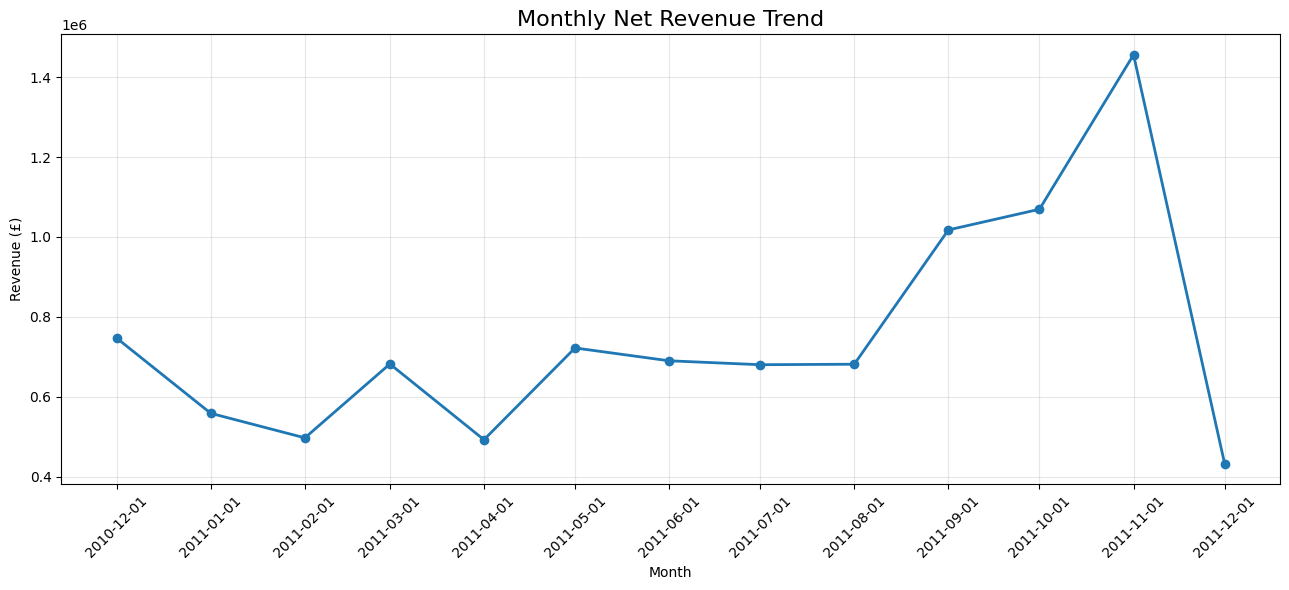

Highest revenue month: November 2011 — £ 1456145.8
Lowest revenue month: December 2011 — £ 432701.06


In [13]:

import matplotlib.pyplot as plt
import pandas as pd

chart_df = monthly_summary.copy()
chart_df["Month"] = pd.to_datetime(chart_df["Month"])

highest_month = chart_df.loc[
    chart_df["Total_Revenue"].idxmax()
]

lowest_month = chart_df.loc[
    chart_df["Total_Revenue"].idxmin()
]

plt.figure(figsize=(13, 6))

plt.plot(
    chart_df["Month"],
    chart_df["Total_Revenue"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Net Revenue Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(chart_df["Month"], rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Highest revenue month:",
      highest_month["Month"].strftime("%B %Y"),
      "— £", round(highest_month["Total_Revenue"], 2))

print("Lowest revenue month:",
      lowest_month["Month"].strftime("%B %Y"),
      "— £", round(lowest_month["Total_Revenue"], 2))


## 13. Country performance

Rank countries by net revenue and summarise invoice counts, positive units sold, and identifiable customers.

In [14]:

country_summary = (
    clean_df.groupby("Country")
    .agg(
        Net_Revenue=("Revenue", "sum"),
        Invoice_Count=("InvoiceNo", "nunique"),
        Units_Sold=("Quantity", lambda x: x[x > 0].sum()),
        Unique_Customers=("CustomerID", "nunique")
    )
    .sort_values("Net_Revenue", ascending=False)
    .reset_index()
)

country_summary["Net_Revenue"] = country_summary["Net_Revenue"].round(2)

print("Top 10 countries by net revenue")
display(country_summary.head(10))




Top 10 countries by net revenue


,Country,Net_Revenue,Invoice_Count,Units_Sold,Unique_Customers
0,United Kingdom,8167128.18,23494,4718329,3950
1,Netherlands,284661.54,101,200937,9
2,EIRE,262993.38,360,147281,3
3,Germany,221509.47,603,119156,95
4,France,197317.11,461,112061,87
5,Australia,137009.77,69,84199,9
6,Switzerland,56363.05,74,30618,21
7,Spain,54756.03,105,27944,31
8,Belgium,40910.96,119,23237,25
9,Sweden,36585.41,46,36078,8


## 14. Country revenue chart

Plot the ten highest-revenue countries to compare the scale of each market.

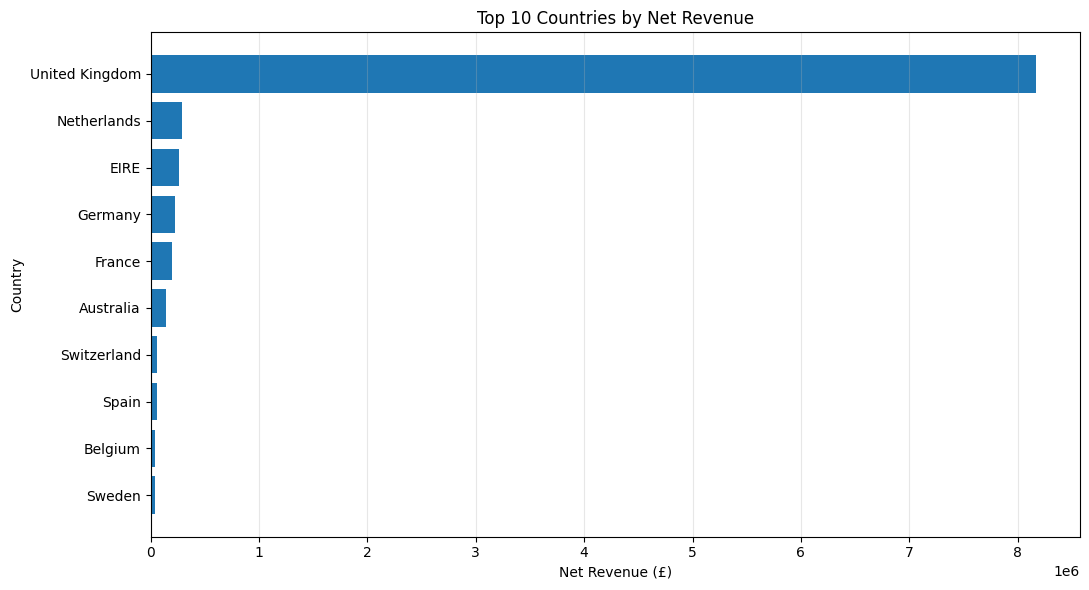

In [15]:

import matplotlib.pyplot as plt

top_countries = country_summary.head(10).sort_values(
    "Net_Revenue", ascending=True
)

plt.figure(figsize=(11, 6))

plt.barh(
    top_countries["Country"],
    top_countries["Net_Revenue"]
)

plt.title("Top 10 Countries by Net Revenue")
plt.xlabel("Net Revenue (£)")
plt.ylabel("Country")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


## 15. Top products by revenue

Rank descriptions using positive quantities and positive unit prices. This initial ranking may include service-like descriptions such as postage, so review the next section for regular products.

,Description,Revenue,Units_Sold,Invoice_Count
0,DOTCOM POSTAGE,206248.77,706,706
1,REGENCY CAKESTAND 3 TIER,174156.54,13851,1988
2,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
3,WHITE HANGING HEART T-LIGHT HOLDER,106236.72,37872,2256
4,PARTY BUNTING,99445.23,18283,1685
5,JUMBO BAG RED RETROSPOT,94159.81,48371,2089
6,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247
7,POSTAGE,78101.88,3150,1126
8,Manual,77752.82,6985,290
9,RABBIT NIGHT LIGHT,66870.03,30739,994


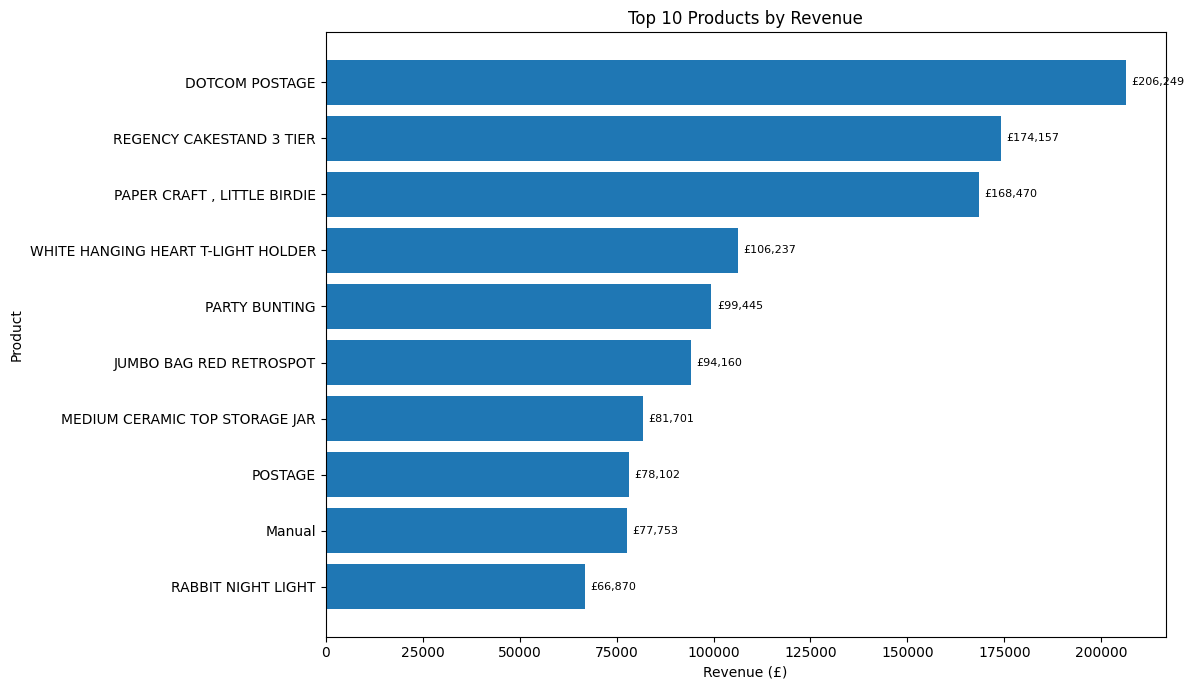

In [16]:

product_df = clean_df.copy()

product_df["Revenue"] = (
    product_df["Quantity"] * product_df["UnitPrice"]
)

top_products = (
    product_df[(product_df["Quantity"] > 0) & (product_df["UnitPrice"] > 0)]
    .groupby("Description")
    .agg(
        Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Invoice_Count=("InvoiceNo", "nunique")
    )
    .sort_values("Revenue", ascending=False)
    .head(10)
    .reset_index()
)

top_products["Revenue"] = top_products["Revenue"].round(2)

display(top_products)

chart_products = top_products.sort_values(
    "Revenue", ascending=True
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    chart_products["Description"],
    chart_products["Revenue"]
)

plt.bar_label(
    bars,
    labels=[f"£{value:,.0f}" for value in chart_products["Revenue"]],
    padding=4,
    fontsize=8
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()



## 16. Regular-product performance

Exclude selected service/non-standard description keywords and require positive quantity and positive unit price before ranking regular products. The keyword rule is a practical heuristic, not a perfect product taxonomy.

In [17]:

product_analysis_df = clean_df.copy()

product_analysis_df["Revenue"] = (
    product_analysis_df["Quantity"] *
    product_analysis_df["UnitPrice"]
)

product_analysis_df["Description"] = (
    product_analysis_df["Description"]
    .astype("string")
    .str.strip()
)

non_standard_keywords = r"POSTAGE|DOTCOM|MANUAL|BANK CHARGES|CARRIAGE"

product_analysis_df["Product_Type"] = np.where(
    product_analysis_df["Description"]
    .str.contains(non_standard_keywords, case=False, na=False),
    "Non-standard / Service",
    "Regular Product"
)

regular_products = product_analysis_df[
    (product_analysis_df["Quantity"] > 0) &
    (product_analysis_df["UnitPrice"] > 0) &
    (product_analysis_df["Product_Type"] == "Regular Product")
].copy()

regular_product_summary = (
    regular_products.groupby("Description")
    .agg(
        Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Invoice_Count=("InvoiceNo", "nunique")
    )
    .sort_values("Revenue", ascending=False)
    .head(10)
    .reset_index()
)

regular_product_summary["Revenue"] = (
    regular_product_summary["Revenue"].round(2)
)

display(regular_product_summary)


,Description,Revenue,Units_Sold,Invoice_Count
0,REGENCY CAKESTAND 3 TIER,174156.54,13851,1988
1,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
2,WHITE HANGING HEART T-LIGHT HOLDER,106236.72,37872,2256
3,PARTY BUNTING,99445.23,18283,1685
4,JUMBO BAG RED RETROSPOT,94159.81,48371,2089
5,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247
6,RABBIT NIGHT LIGHT,66870.03,30739,994
7,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59,19329,1160
8,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362,1455
9,CHILLI LIGHTS,54096.36,10302,661


## 17. Customer-level analysis

Exclude rows without a customer ID only for customer-level analysis, then calculate each identified customer’s net revenue, invoice count, positive units purchased, first/last purchase, and repeat-customer flag.

In [18]:

customer_df = clean_df.dropna(
    subset=["CustomerID"]
).copy()

customer_df["CustomerID"] = (
    customer_df["CustomerID"].astype("Int64").astype("string")
)

customer_df["Revenue"] = (
    customer_df["Quantity"] * customer_df["UnitPrice"]
)

customer_summary = (
    customer_df.groupby("CustomerID")
    .agg(
        Net_Revenue=("Revenue", "sum"),
        Invoice_Count=("InvoiceNo", "nunique"),
        Units_Purchased=(
            "Quantity",
            lambda x: x[x > 0].sum()
        ),
        First_Purchase=("InvoiceDate", "min"),
        Last_Purchase=("InvoiceDate", "max")
    )
    .reset_index()
)

customer_summary["Net_Revenue"] = (
    customer_summary["Net_Revenue"].round(2)
)

customer_summary["Repeat_Customer"] = (
    customer_summary["Invoice_Count"] > 1
)

print("Identified customers:", len(customer_summary))
print("Customers with multiple invoices:",
      int(customer_summary["Repeat_Customer"].sum()))

print("\nTop 10 customers by net revenue")
display(
    customer_summary
    .sort_values("Net_Revenue", ascending=False)
    .head(10)
)


Identified customers: 4372
Customers with multiple invoices: 3059

Top 10 customers by net revenue


,CustomerID,Net_Revenue,Invoice_Count,Units_Purchased,First_Purchase,Last_Purchase,Repeat_Customer
1703,14646,279489.02,77,197491,2010-12-20 10:09:00,2011-12-08 12:12:00,True
4233,18102,256438.49,62,64124,2010-12-07 16:42:00,2011-12-09 11:50:00,True
3758,17450,187322.17,55,69973,2010-12-07 09:23:00,2011-12-01 13:29:00,True
1895,14911,132458.73,248,80490,2010-12-01 14:05:00,2011-12-08 15:54:00,True
55,12415,123725.45,26,77670,2011-01-06 11:12:00,2011-11-15 14:22:00,True
1345,14156,113214.59,66,57768,2010-12-02 17:08:00,2011-11-30 10:54:00,True
3801,17511,88125.38,46,64549,2010-12-01 10:19:00,2011-12-07 10:12:00,True
3202,16684,65892.08,31,50255,2010-12-16 17:34:00,2011-12-05 14:06:00,True
1005,13694,62690.54,60,63312,2010-12-01 12:12:00,2011-12-06 09:32:00,True
2192,15311,59284.19,118,38147,2010-12-01 09:41:00,2011-12-09 12:00:00,True


## 18. Customer revenue concentration

Calculate each identified customer’s share of total identified-customer net revenue and the cumulative share after ranking by revenue. This indicates revenue concentration within the identifiable customer base.

In [19]:

customer_ranked = customer_summary.sort_values(
    "Net_Revenue", ascending=False
).copy()

total_customer_net_revenue = customer_ranked[
    "Net_Revenue"
].sum()

if customer_ranked.empty or abs(total_customer_net_revenue) < 1e-12:
    customer_ranked["Revenue_Share_Pct"] = 0.0
else:
    customer_ranked["Revenue_Share_Pct"] = (
        customer_ranked["Net_Revenue"]
        / total_customer_net_revenue * 100
    )

customer_ranked["Cumulative_Revenue_Share_Pct"] = (
    customer_ranked["Revenue_Share_Pct"].cumsum()
)

top_10_share = customer_ranked.head(10)[
    "Revenue_Share_Pct"
].sum()

top_50_share = customer_ranked.head(50)[
    "Revenue_Share_Pct"
].sum()

print("Identified customers:", len(customer_ranked))
print("Top 10 customer revenue share (%):", round(top_10_share, 2))
print("Top 50 customer revenue share (%):", round(top_50_share, 2))

print("\nTop 10 customers with revenue share")
display(
    customer_ranked[
        [
            "CustomerID",
            "Net_Revenue",
            "Invoice_Count",
            "Revenue_Share_Pct",
            "Cumulative_Revenue_Share_Pct"
        ]
    ].head(10).round(2)
)


Identified customers: 4372
Top 10 customer revenue share (%): 16.53
Top 50 customer revenue share (%): 31.21

Top 10 customers with revenue share


,CustomerID,Net_Revenue,Invoice_Count,Revenue_Share_Pct,Cumulative_Revenue_Share_Pct
1703,14646,279489.02,77,3.38,3.38
4233,18102,256438.49,62,3.10,6.47
3758,17450,187322.17,55,2.26,8.74
1895,14911,132458.73,248,1.60,10.34
55,12415,123725.45,26,1.49,11.83
1345,14156,113214.59,66,1.37,13.20
3801,17511,88125.38,46,1.06,14.26
3202,16684,65892.08,31,0.80,15.06
1005,13694,62690.54,60,0.76,15.82
2192,15311,59284.19,118,0.72,16.53


## 19. Final validation checks

Run these checks after the cleaned table and summary tables are created. They confirm row-level deduplication, revenue arithmetic, and basic report integrity before export.

In [20]:
required_columns = {"InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "InvoiceDate", "CustomerID", "Country", "Revenue"}
missing_columns = required_columns.difference(clean_df.columns)
assert not missing_columns, f"Missing required columns: {sorted(missing_columns)}"
assert not clean_df.duplicated().any(), "Exact duplicate rows remain in clean_df."
assert clean_df["Revenue"].notna().all(), "Revenue contains missing values; inspect Quantity/UnitPrice."
assert (clean_df["Revenue"].round(2) == (clean_df["Quantity"] * clean_df["UnitPrice"]).round(2)).all(), "Revenue does not match Quantity × UnitPrice."
assert not monthly_summary.empty, "Monthly summary is empty."
assert not country_summary.empty, "Country summary is empty."
assert not top_products.empty, "Top-products summary is empty."
print("Validation passed")
print("Clean rows:", len(clean_df))
print("Monthly periods:", len(monthly_summary))
print("Countries:", len(country_summary))
print("Top product rows:", len(top_products))


Validation passed
Clean rows: 536641
Monthly periods: 13
Countries: 38
Top product rows: 10


## 20. Export analysis reports

Write the summary tables and cleaned transaction data to the output directory. The exception report is created earlier in the workflow and remains in the same directory.

In [21]:

from pathlib import Path

output_dir = Path("/content/business_intelligence_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

reports = {
    "monthly_revenue_summary.csv": monthly_summary,
    "country_performance.csv": country_summary,
    "top_10_products.csv": top_products,
    "top_10_regular_products.csv": regular_product_summary,
    "customer_summary.csv": customer_summary,
    "customer_revenue_concentration.csv": customer_ranked,
    "data_quality_summary.csv": issue_summary,
    "data_quality_exceptions.csv": exception_df,
}

for filename, report_df in reports.items():
    report_df.to_csv(output_dir / filename, index=False)

clean_df.to_csv(
    output_dir / "cleaned_transactions.csv",
    index=False
)

print("Reports exported successfully:\n")

for file_path in sorted(output_dir.glob("*.csv")):
    print(f"{file_path.name} — {file_path.stat().st_size / 1024:.1f} KB")

print("\nTotal CSV files:", len(list(output_dir.glob("*.csv"))))


Reports exported successfully:

cleaned_transactions.csv — 59383.3 KB
country_performance.csv — 1.1 KB
customer_revenue_concentration.csv — 442.1 KB
customer_summary.csv — 276.2 KB
data_quality_exceptions.csv — 16531.5 KB
data_quality_summary.csv — 0.3 KB
monthly_revenue_summary.csv — 0.6 KB
top_10_products.csv — 0.4 KB
top_10_regular_products.csv — 0.5 KB

Total CSV files: 9


## 21. Package reports for download

Create a ZIP archive of the exported CSV files so the outputs can be downloaded from Google Colab.

In [22]:

import shutil
from pathlib import Path

output_dir = Path("/content/business_intelligence_outputs")
zip_path = shutil.make_archive(
    "/content/business_intelligence_project_reports",
    "zip",
    root_dir=output_dir
)

print("ZIP created:", zip_path)
print("Size (MB):", round(Path(zip_path).stat().st_size / (1024 * 1024), 2))


ZIP created: /content/business_intelligence_project_reports.zip
Size (MB): 11.66


## 22. Project notes and interpretation

- Revenue is calculated as `Quantity × UnitPrice`; negative quantities and cancellation invoices affect net revenue.
- Missing `CustomerID` values are retained in overall transaction and country analysis but omitted from customer-level grouping.
- Exact duplicate removal is an explicit assumption; document it when presenting results because repeated-looking invoice lines can require business-context review.
- The final dataset month is December 2011, which is incomplete in the source data.
- CSV outputs are saved under `/content/business_intelligence_outputs/` in the Colab runtime; download them before the runtime is reset.

- The final December 2011 period is incomplete; do not compare it directly with full calendar months without noting the partial period.
- Customer-level metrics exclude rows with missing CustomerID, while overall and country-level summaries retain them.
- Top-product and regular-product lists are revenue rankings, not proof of product quality or profitability; the non-standard keyword filter is a heuristic.
- Run the notebook from top to bottom in a fresh Google Colab runtime before publishing results. The dataset download requires internet access.